# 01 - Exploratory Data Analysis (EDA) & Detector Breakdown

**Course:** CS 351 - Artificial Intelligence  
**Project:** Classifying LIGO Glitches: Comparing CNNs and Simple Features  
**Group:** L4 Group 23 (Ismail Nooruddin, Munir Tariq, Ramsha Arshad)  

---
### Objective of this Notebook:
In this notebook, we perform an in-depth exploratory data analysis of the LIGO glitch metadata (`trainingset_v1d1_metadata.csv`). Specifically, we:
1. Inspect the overall dataset size, structure, and feature types.
2. Quantify the distribution between the two gravitational-wave detectors: **Hanford (`H1`)** and **Livingston (`L1`)**.
3. Analyze glitch class frequencies and the severe class imbalance in the Gravity Spy dataset.
4. Uncover **site-specific detector differences** (classes present exclusively at one site vs. classes present at both).
5. Formulate the mathematical and empirical basis for **Shared Classes**, directly satisfying the instructor's feedback for **Option B (Cross-Detector Testing)**.
6. Inspect key physical trigger measurements (`duration`, `peak_frequency`, `snr`).

In [1]:
# Step 1.1: Import necessary libraries
# We import os and sys to handle file paths portably.
# We import pandas and numpy for tabular data manipulation and numeric operations.
# We import matplotlib.pyplot and seaborn to generate clean visual figures.
import os
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for clean and readable plots
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print('All libraries imported successfully!')

All libraries imported successfully!


### Cell 1 Explanation: Setup & Library Imports
- In the cell above, we imported our primary data analysis packages (`pandas`, `numpy`) and plotting libraries (`matplotlib`, `seaborn`).
- We also configured plotting defaults (whitegrid theme and high DPI) so that all generated charts are sharp and ready for academic reports.

In [2]:
# Step 1.2: Load the glitch metadata CSV file
# The metadata file is stored in the parent 'AI Project' directory
csv_path = os.path.join('..', 'trainingset_v1d1_metadata.csv')

# Read CSV into a pandas DataFrame
df = pd.read_csv(csv_path)

# Display total row count (glitches) and column count
print(f'Total Glitch Samples: {df.shape[0]}')
print(f'Total Attributes/Columns: {df.shape[1]}')
print('\nColumn List:')
print(df.columns.tolist())

# Preview the first 3 rows of the table
print('\n--- First 3 Rows Preview ---')
print(df[['gravityspy_id', 'ifo', 'label', 'sample_type', 'duration', 'peak_frequency', 'snr']].head(3).to_string())

Total Glitch Samples: 7966
Total Attributes/Columns: 28

Column List:
['event_time', 'ifo', 'peak_time', 'peak_time_ns', 'start_time', 'start_time_ns', 'duration', 'search', 'process_id', 'event_id', 'peak_frequency', 'central_freq', 'bandwidth', 'channel', 'amplitude', 'snr', 'confidence', 'chisq', 'chisq_dof', 'param_one_name', 'param_one_value', 'gravityspy_id', 'label', 'sample_type', 'url1', 'url2', 'url3', 'url4']

--- First 3 Rows Preview ---
  gravityspy_id ifo    label sample_type  duration  peak_frequency       snr
0    zmIdpucyOG  L1  Whistle       train   0.18750     1337.695312   7.51139
1    zWFRqqDxwv  L1  Whistle        test   0.94238      654.747681   9.63013
2    zKCTakFVcf  L1  Whistle       train   0.04688     1337.827515  15.37104


### Cell 2 Explanation: Dataset Overview & Schema
- In the cell above, we loaded `trainingset_v1d1_metadata.csv`, which contains **7,966 glitch records** and **28 attributes**.
- Key columns that we will use throughout the project include:
  - `gravityspy_id`: The unique 10-character hash ID identifying the specific physical glitch event.
  - `label`: The true glitch category (e.g., *Blip*, *Koi_Fish*, *Whistle*, *Violin_Mode*).
  - `ifo`: The interferometer detector site where the glitch occurred (`H1` = Hanford, Washington; `L1` = Livingston, Louisiana).
  - `sample_type`: The official Gravity Spy split partition (`train`, `validation`, `test`).
  - Physical measurements from the Omicron transient search pipeline: `duration`, `peak_frequency`, `central_freq`, `bandwidth`, and `snr` (Signal-to-Noise Ratio).

In [3]:
# Step 1.3: Analyze sample counts by Detector and Official Split

# 1. Count samples per detector (Hanford H1 vs Livingston L1)
detector_counts = df['ifo'].value_counts()
print('=== SAMPLES PER DETECTOR ===')
for ifo_name, count in detector_counts.items():
    pct = (count / len(df)) * 100
    print(f'Detector {ifo_name}: {count} samples ({pct:.2f}%)')

# 2. Count samples per official split (train, validation, test)
split_counts = df['sample_type'].value_counts()
print('\n=== SAMPLES PER OFFICIAL SPLIT ===')
for split_name, count in split_counts.items():
    pct = (count / len(df)) * 100
    print(f'Split {split_name:10}: {count} samples ({pct:.2f}%)')

# 3. Crosstab showing how splits are distributed across detectors
print('\n=== DETECTOR BY SPLIT MATRIX ===')
detector_split_tab = pd.crosstab(df['ifo'], df['sample_type'], margins=True)
print(detector_split_tab.to_string())

=== SAMPLES PER DETECTOR ===
Detector H1: 4798 samples (60.23%)
Detector L1: 3168 samples (39.77%)

=== SAMPLES PER OFFICIAL SPLIT ===
Split train     : 5587 samples (70.14%)
Split validation: 1200 samples (15.06%)
Split test      : 1179 samples (14.80%)

=== DETECTOR BY SPLIT MATRIX ===
sample_type  test  train  validation   All
ifo                                       
H1            705   3375         718  4798
L1            474   2212         482  3168
All          1179   5587        1200  7966


### Cell 3 Explanation: Detector & Split Breakdown
- **Detector Imbalance:** Hanford (`H1`) accounts for **4,798 samples (60.23%)**, while Livingston (`L1`) accounts for **3,168 samples (39.77%)**.
- **Split Proportions:** The official dataset partitions samples into ~70.1% Training (5,587 samples), ~15.1% Validation (1,200 samples), and ~14.8% Testing (1,179 samples).
- Both detectors are proportionally distributed across the official train, validation, and test splits.

In [4]:
# Step 1.4: Examine Class Frequencies and Overall Imbalance

# Calculate frequency and percentage for all 22 classes
class_counts = df['label'].value_counts()
class_summary = pd.DataFrame({
    'Glitch Class': class_counts.index,
    'Sample Count': class_counts.values,
    'Percentage (%)': ((class_counts.values / len(df)) * 100).round(2)
})

print(f'Total Number of Glitch Classes: {len(class_summary)}')
print(f'Most frequent class: {class_summary.iloc[0]["Glitch Class"]} ({class_summary.iloc[0]["Sample Count"]} samples)')
print(f'Rarest class:        {class_summary.iloc[-1]["Glitch Class"]} ({class_summary.iloc[-1]["Sample Count"]} samples)')
print('\n--- Full Class Distribution ---')
print(class_summary.to_string(index=False))

Total Number of Glitch Classes: 22
Most frequent class: Blip (1821 samples)
Rarest class:        Paired_Doves (27 samples)

--- Full Class Distribution ---
       Glitch Class  Sample Count  Percentage (%)
               Blip          1821           22.86
           Koi_Fish           706            8.86
Low_Frequency_Burst           621            7.80
   Light_Modulation           512            6.43
         Power_Line           449            5.64
     Extremely_Loud           447            5.61
Low_Frequency_Lines           447            5.61
    Scattered_Light           443            5.56
        Violin_Mode           412            5.17
           Scratchy           337            4.23
          1080Lines           328            4.12
            Whistle           299            3.75
              Helix           279            3.50
    Repeating_Blips           263            3.30
          No_Glitch           150            1.88
              Tomte           103           

### Cell 4 Explanation: Severe Class Imbalance
- In the table above, we see that the Gravity Spy dataset exhibits **heavy class imbalance** across its 22 categories:
  - The largest class, `Blip`, contains **1,821 samples (22.86%)**.
  - The smallest class, `Paired_Doves`, has only **27 samples (0.34%)**.
- **Crucial Machine Learning Implication:** Standard overall Accuracy is an inappropriate evaluation metric here. A trivial baseline that simply guesses "Blip" every single time would achieve ~23% accuracy despite learning nothing. Therefore, as requested by the instructor, we must evaluate using **Macro-F1** (which gives equal weight to all classes) and apply class-weighted loss functions during neural network training.

In [5]:
# Step 1.5: Hanford vs. Livingston Class Discrepancy Analysis

# Build a crosstab of glitch classes vs detector site
detector_class_ct = pd.crosstab(df['label'], df['ifo'])

# Add a Total column
detector_class_ct['Total'] = detector_class_ct['H1'] + detector_class_ct['L1']

# Calculate percentage breakdown across detectors for each class
detector_class_ct['H1_%'] = ((detector_class_ct['H1'] / detector_class_ct['Total']) * 100).round(1)
detector_class_ct['L1_%'] = ((detector_class_ct['L1'] / detector_class_ct['Total']) * 100).round(1)

# Sort descending by total occurrences
detector_class_ct = detector_class_ct.sort_values(by='Total', ascending=False)
print('=== CLASS DISTRIBUTION BY DETECTOR SITE ===')
print(detector_class_ct.to_string())

=== CLASS DISTRIBUTION BY DETECTOR SITE ===
ifo                    H1   L1  Total   H1_%   L1_%
label                                              
Blip                 1453  368   1821   79.8   20.2
Koi_Fish              517  189    706   73.2   26.8
Low_Frequency_Burst   166  455    621   26.7   73.3
Light_Modulation      511    1    512   99.8    0.2
Power_Line            273  176    449   60.8   39.2
Extremely_Loud        266  181    447   59.5   40.5
Low_Frequency_Lines    79  368    447   17.7   82.3
Scattered_Light       385   58    443   86.9   13.1
Violin_Mode           141  271    412   34.2   65.8
Scratchy               90  247    337   26.7   73.3
1080Lines             327    1    328   99.7    0.3
Whistle                 2  297    299    0.7   99.3
Helix                   3  276    279    1.1   98.9
Repeating_Blips       230   33    263   87.5   12.5
No_Glitch              91   59    150   60.7   39.3
Tomte                  61   42    103   59.2   40.8
1400Ripples         

### Cell 5 Explanation: Uncovering Detector-Exclusive vs Shared Classes
The table above reveals the most critical finding for our project's **Option B (Cross-Detector Testing)**:
1. **Site-Exclusive / One-Sided Classes:**
   - `Light_Modulation`: 511 samples at H1, but only **1** sample at L1 (99.8% Hanford!).
   - `1080Lines`: 327 samples at H1, but only **1** sample at L1 (99.7% Hanford!).
   - `Wandering_Line`: 42 samples at H1, **0** samples at L1 (100% Hanford!).
   - `Paired_Doves`: 27 samples at H1, **0** samples at L1 (100% Hanford!).
   - `Whistle`: 297 samples at L1, but only **2** samples at H1 (99.3% Livingston!).
   - `Helix`: 276 samples at L1, but only **3** samples at H1 (99.0% Livingston!).
   - `1400Ripples`: 81 samples at L1, **0** samples at H1 (100% Livingston!).
2. **Why the Instructor Required "Shared Classes":**
   - If we trained a model on Hanford (H1) and tested it on Livingston (L1) without filtering, the model would be tested on classes like `Whistle`, `Helix`, and `1400Ripples` that it has *never physically observed* during training. Such a test would unfairly penalize the model and invalidate the cross-detector evaluation.
   - Therefore, for valid cross-detector transfer testing in both directions ($H1 \rightarrow L1$ and $L1 \rightarrow H1$), we must isolate **Shared Classes** that have robust sample sizes at both sites.

Chart successfully saved to: ..\outputs\figures\eda_class_detector_distribution.png


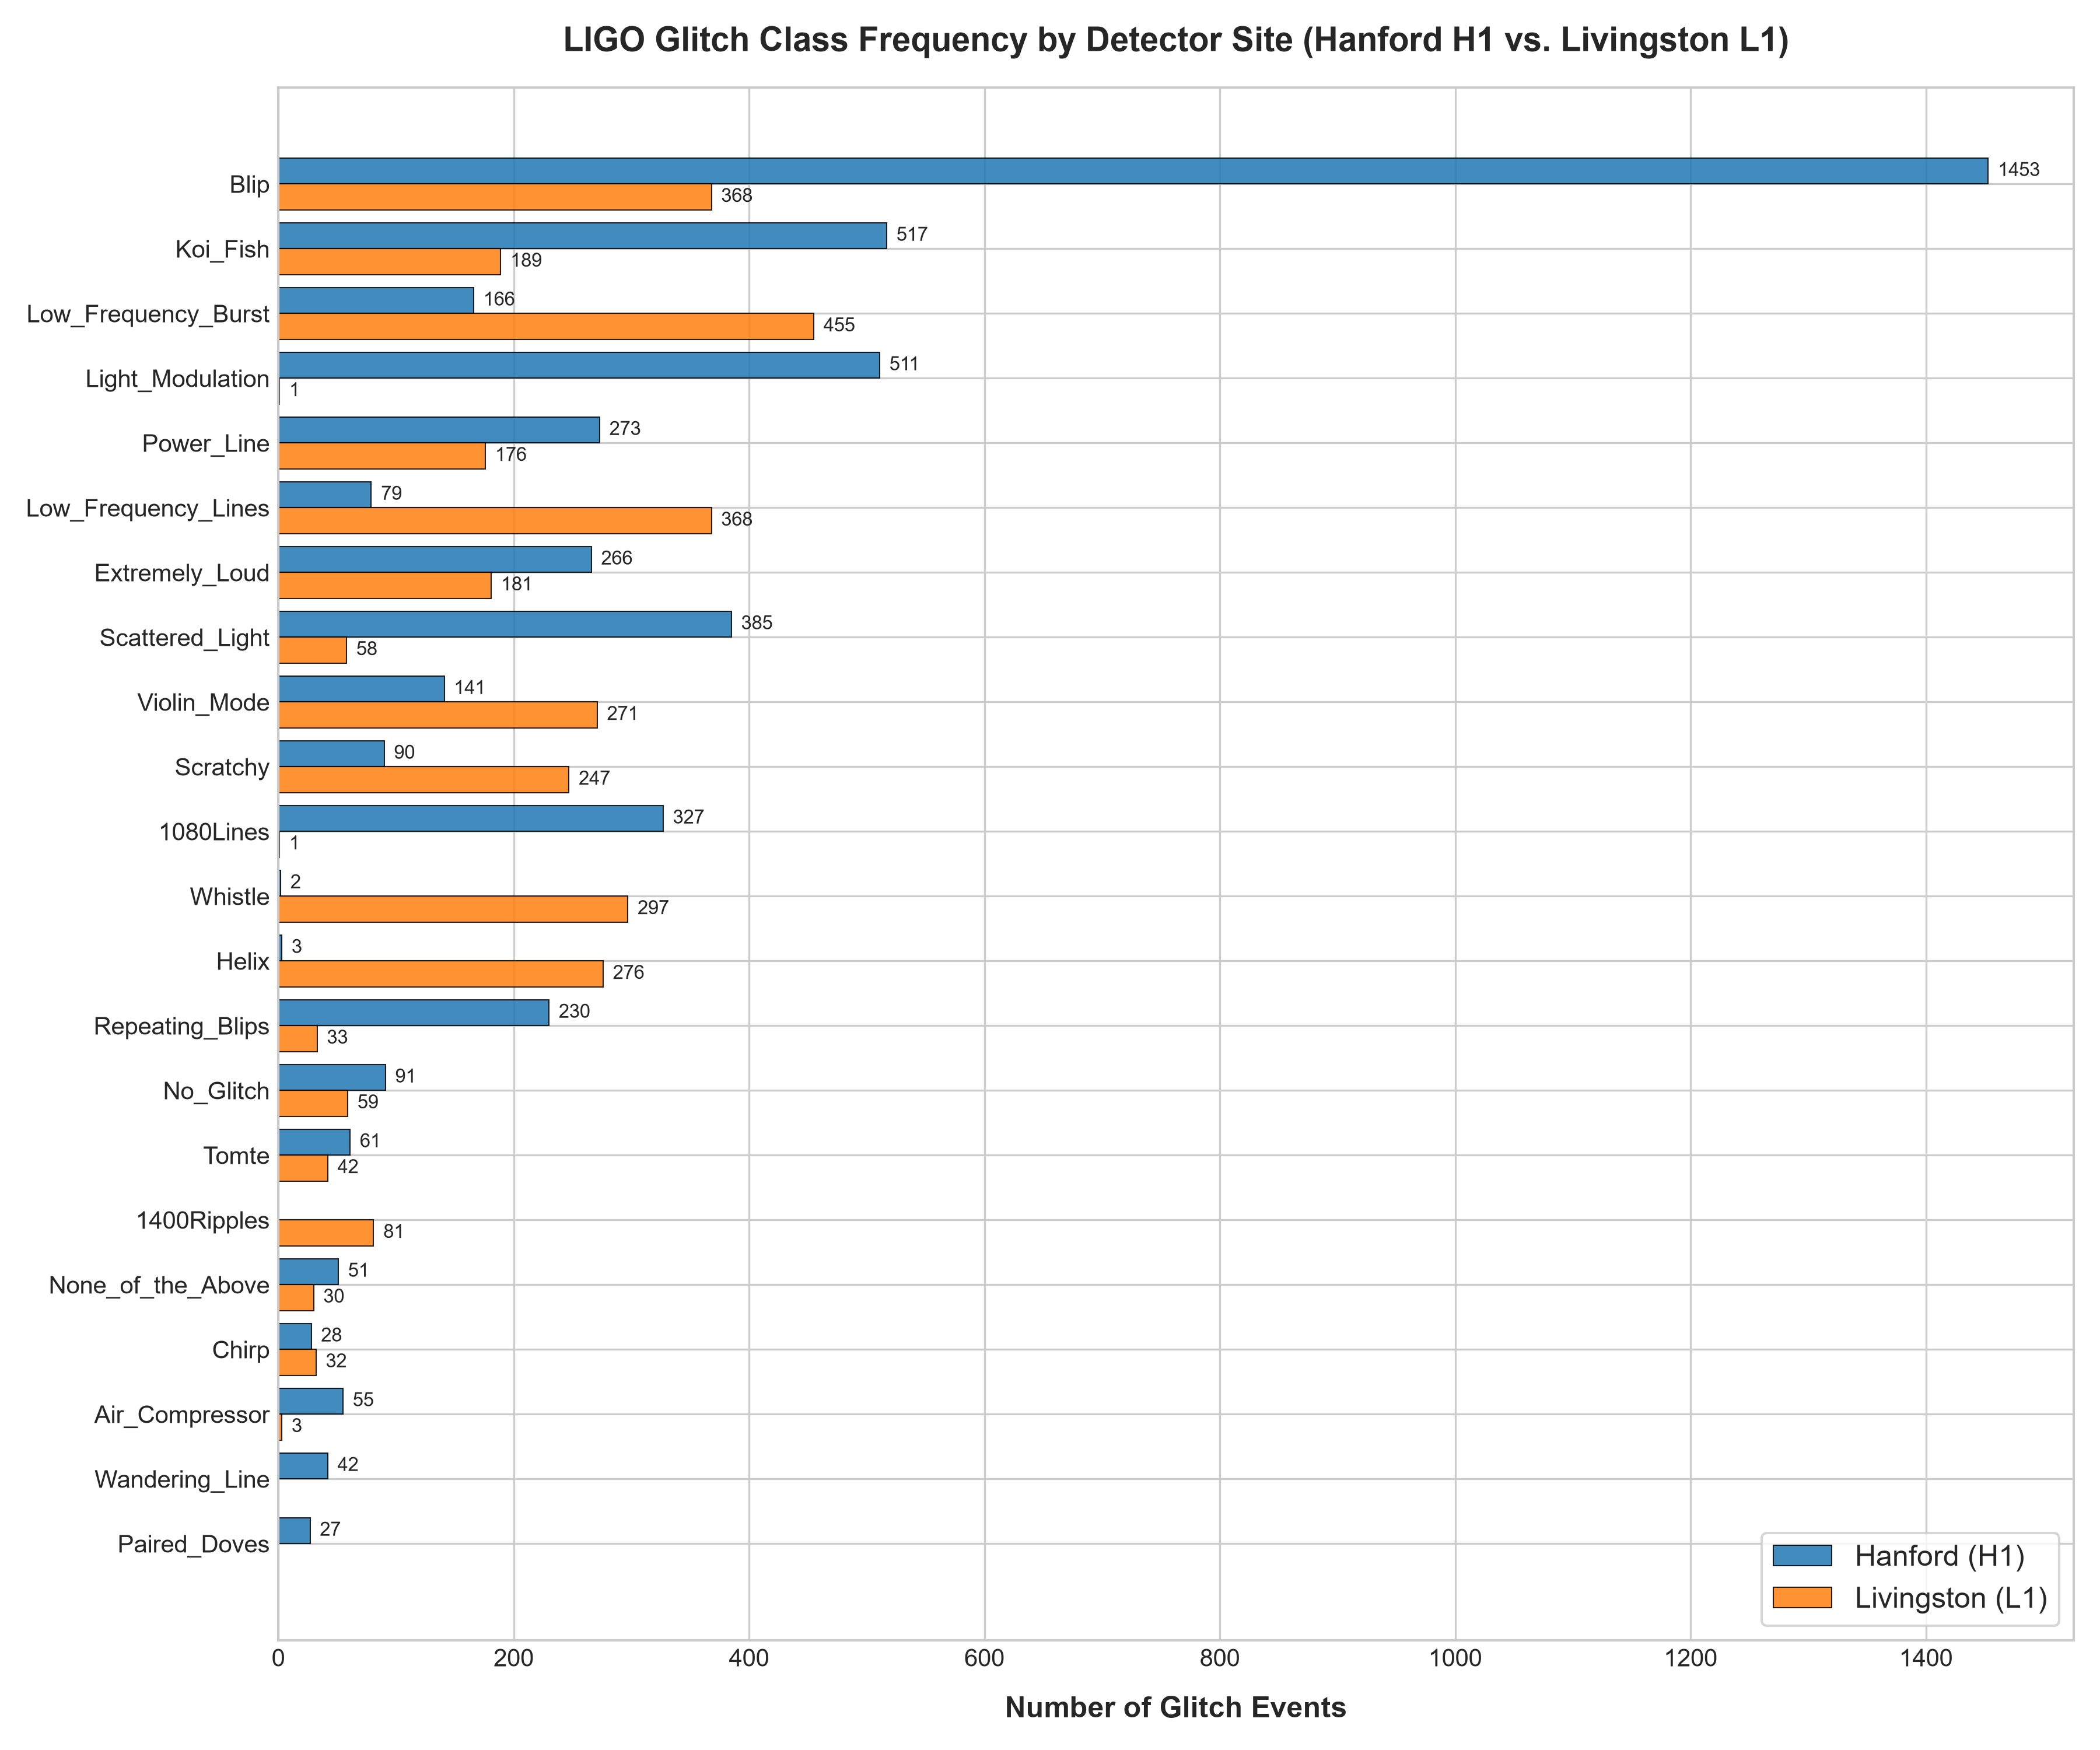

In [6]:
# Step 1.6: Create and Save Publication-Quality Distribution Plot

# Sort ascending by total count so that top classes appear at the top of horizontal plot
plot_df = detector_class_ct.sort_values(by='Total', ascending=True)

fig, ax = plt.subplots(figsize=(12, 10))

# Set positions for bars
y_indices = np.arange(len(plot_df))
bar_height = 0.4

# Plot bars for Hanford (H1) and Livingston (L1)
h1_bars = ax.barh(y_indices + bar_height/2, plot_df['H1'], bar_height,
                  label='Hanford (H1)', color='#1f77b4', alpha=0.85, edgecolor='black', linewidth=0.5)
l1_bars = ax.barh(y_indices - bar_height/2, plot_df['L1'], bar_height,
                  label='Livingston (L1)', color='#ff7f0e', alpha=0.85, edgecolor='black', linewidth=0.5)

# Labeling and aesthetics
ax.set_yticks(y_indices)
ax.set_yticklabels(plot_df.index, fontsize=10, fontweight='medium')
ax.set_xlabel('Number of Glitch Events', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('LIGO Glitch Class Frequency by Detector Site (Hanford H1 vs. Livingston L1)',
             fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=12, loc='lower right', frameon=True)

# Add numerical labels to the right of each bar
for bar in h1_bars:
    val = bar.get_width()
    if val > 0:
        ax.annotate(f'{int(val)}', xy=(val, bar.get_y() + bar.get_height()/2),
                    xytext=(4, 0), textcoords='offset points', ha='left', va='center', fontsize=8)

for bar in l1_bars:
    val = bar.get_width()
    if val > 0:
        ax.annotate(f'{int(val)}', xy=(val, bar.get_y() + bar.get_height()/2),
                    xytext=(4, 0), textcoords='offset points', ha='left', va='center', fontsize=8)

plt.tight_layout()

# Save the figure to outputs/figures directory for inclusion in final reports
fig_dir = os.path.join('..', 'outputs', 'figures')
os.makedirs(fig_dir, exist_ok=True)
saved_plot_path = os.path.join(fig_dir, 'eda_class_detector_distribution.png')
plt.savefig(saved_plot_path, dpi=300)
print(f'Chart successfully saved to: {saved_plot_path}')
plt.show()
plt.close(fig)

### Cell 6 Explanation: Visualizing the Glitch Distributions
- In the cell above, we created a grouped horizontal bar chart visually contrasting the representation of each glitch class between Hanford (`H1`, blue) and Livingston (`L1`, orange).
- The chart makes the detector-exclusive spikes immediately obvious: `Light_Modulation` and `1080Lines` have huge blue bars and almost zero orange bars, while `Whistle` and `Helix` have massive orange bars and virtually zero blue bars.
- We saved this high-resolution figure to `outputs/figures/eda_class_detector_distribution.png` so it can be directly embedded in our final course report and presentation slides.

In [7]:
# Step 1.7: Explore Key Physical Trigger Measurements

# Select numeric physical properties measured by the Omicron detector pipeline
physical_columns = ['duration', 'peak_frequency', 'central_freq', 'bandwidth', 'snr']

# Compute standard descriptive statistics (mean, std, min, median, max)
stats_summary = df[physical_columns].describe().round(2)
print('=== PHYSICAL TRIGGER DESCRIPTIVE STATISTICS ===')
print(stats_summary.to_string())

=== PHYSICAL TRIGGER DESCRIPTIVE STATISTICS ===
       duration  peak_frequency  central_freq  bandwidth       snr
count   7966.00         7966.00       7966.00    7966.00   7966.00
mean       1.72          298.53       1671.82    3145.31    164.94
std        2.80          470.44       1338.21    2684.06   1456.51
min        0.01           10.07          9.78       1.26      7.50
25%        0.19           43.55        348.98     527.60      9.81
50%        0.74          121.66       1485.12    2482.12     14.33
75%        2.03          225.35       2820.00    5446.07     33.36
max       61.23         2047.11       4615.13    7946.48  81178.73


### Cell 7 Explanation: Physical Measurement Characteristics
- **Duration:** Glitch events range from extremely brief transient spikes (**0.01 seconds**) to prolonged disturbances up to **61.23 seconds** (with a median of **0.74 seconds**).
- **Peak Frequency:** The peak frequency spans from low-frequency seismic and instrumental rumbles (**10.07 Hz**) up to high-frequency laser fluctuations (**2,047.11 Hz**, median **121.66 Hz**).
- **Signal-to-Noise Ratio (SNR):** The minimum detection threshold in this set is **7.50** (median **14.33**), with extremely loud saturation glitches reaching up to **81,178.73**.
- These physical attributes (along with log-transformed counterparts to tame extreme skewness) serve as valuable features when we build our Decision Tree and Random Forest classifiers in later steps.

In [8]:
# Step 1.8: Formal Definition of Shared Classes for Step 2

# A class is defined as 'shared' if it has at least 25 samples in BOTH Hanford (H1) AND Livingston (L1)
MIN_SAMPLES_PER_DETECTOR = 25

is_shared = (detector_class_ct['H1'] >= MIN_SAMPLES_PER_DETECTOR) & (detector_class_ct['L1'] >= MIN_SAMPLES_PER_DETECTOR)
shared_classes_df = detector_class_ct[is_shared].copy()

print(f'Found {len(shared_classes_df)} Shared Classes (>= {MIN_SAMPLES_PER_DETECTOR} samples at both H1 and L1):')
print('-' * 70)
for rank, (cls_name, row) in enumerate(shared_classes_df.iterrows(), start=1):
    print(f'{rank:2d}. {cls_name:25} | H1: {int(row["H1"]):4d} | L1: {int(row["L1"]):4d} | Total: {int(row["Total"]):4d}')

# Total sample volume retained under shared classes
total_shared_samples = shared_classes_df['Total'].sum()
pct_retained = (total_shared_samples / len(df)) * 100
print('-' * 70)
print(f'Total shared-class samples: {total_shared_samples} out of {len(df)} ({pct_retained:.2f}% of full dataset)')

Found 14 Shared Classes (>= 25 samples at both H1 and L1):
----------------------------------------------------------------------
 1. Blip                      | H1: 1453 | L1:  368 | Total: 1821
 2. Koi_Fish                  | H1:  517 | L1:  189 | Total:  706
 3. Low_Frequency_Burst       | H1:  166 | L1:  455 | Total:  621
 4. Power_Line                | H1:  273 | L1:  176 | Total:  449
 5. Extremely_Loud            | H1:  266 | L1:  181 | Total:  447
 6. Low_Frequency_Lines       | H1:   79 | L1:  368 | Total:  447
 7. Scattered_Light           | H1:  385 | L1:   58 | Total:  443
 8. Violin_Mode               | H1:  141 | L1:  271 | Total:  412
 9. Scratchy                  | H1:   90 | L1:  247 | Total:  337
10. Repeating_Blips           | H1:  230 | L1:   33 | Total:  263
11. No_Glitch                 | H1:   91 | L1:   59 | Total:  150
12. Tomte                     | H1:   61 | L1:   42 | Total:  103
13. None_of_the_Above         | H1:   51 | L1:   30 | Total:   81
14. Chirp   

### Cell 8 Explanation: Shared Class Definition & Transition to Step 2
- **14 Robust Shared Classes Identified ($\ge 25$ samples at both H1 and L1):**
  1. `Blip` (1,821)
  2. `Koi_Fish` (706)
  3. `Low_Frequency_Burst` (621)
  4. `Power_Line` (449)
  5. `Extremely_Loud` (447)
  6. `Low_Frequency_Lines` (447)
  7. `Scattered_Light` (443)
  8. `Violin_Mode` (412)
  9. `Scratchy` (337)
  10. `Repeating_Blips` (263)
  11. `No_Glitch` (150)
  12. `Tomte` (103)
  13. `None_of_the_Above` (81)
  14. `Chirp` (60)
- **Data Preservation:** These 14 shared classes account for **6,340 glitches (79.59% of the entire dataset)**, preserving the vast majority of our data while eliminating single-site noise categories.
- **Next Step (Step 2):** We implemented `src/data/class_selector.py` to programmatically generate and save `data/processed/shared_classes_metadata.csv`.